# SO-SIMBA 

Sea Ice Mass Balance Assessment: Southern Ocean (SO-SIMBA) project aims to develop a comprehensive Antarctic sea ice reference dataset. This dataset will integrate information on thickness, volume, drift,and mass of snow and sea ice from multiple satellite missions such as Envisat, CryoSat-2, Sentinel-3, ICESat-2, SMOS and AMSR-2 as well as other missons.

* Open Science Catalog: https://opensciencedata.esa.int/projects/so-simba/collection
* Landing page : [Arctic Data Centre (MET Norway)](https://adc.met.no/dataset/4e4750fd-66c4-5463-9dcd-5422ea3c8f58) |
* License: CC-BY-4.0


## SO-SIMBA CDR – Antarctic sea-ice thickness

### Overview

The SO-SIMBA Climate Data Record (CDR) of Antarctic sea-ice thickness and volume is derived from radar altimetry
(Envisat 2002–2012, CryoSat-2 2010–2025). Daily L3C files on the 25 km EASE2 grid (EPSG:6932); the position of each ice parcel (10 km radius) is corrected
for the sea-ice drift between the satellite overpass and the target day (drift-aware gridding).

| | |
|---|---|
| **Producers** | Marion Bocquet, Robert Ricker (NORCE Norwegian Research Centre) |
| **Time coverage** | 11 June 2002 – 31 August 2025, daily |
| **Grid** | 25 km EASE2, Southern Hemisphere (EPSG:6932) |
| **DOI** | [10.21343/pf9r-6d17](https://doi.org/10.21343/pf9r-6d17) |
| **Landing page** | [Arctic Data Centre (MET Norway)](https://adc.met.no/dataset/4e4750fd-66c4-5463-9dcd-5422ea3c8f58) |
| **Data server** | [THREDDS catalogue](https://thredds.met.no/thredds/catalog/arcticdata/SO-SIMBA/SOSIMBA_CDR_SIT_vf/catalog.html) (OPeNDAP, HTTP, WMS) |
| **Zarr store** | `https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/so-simba/SOSIMBA_CDR_SIT_vf_<mission>.zarr/` |
| **Licence** | CC-BY-4.0 |
| **Project** | ESA Polar Science Cluster, SO-SIMBA |

This notebook reads the data **remotely, without downloading anything**, from the cloud-optimised **zarr** copy
of the CDR (one store per mission, all days in one dataset):

1. Open the dataset and select one day
2. Map of the sea-ice thickness and its combined uncertainty
3. Time series of the mean sea-ice thickness over a period

The mission is chosen with `MISSION` (`"envisat"` or `"cryosat2"`) at the top; both cover Oct 2010 – Mar 2012.

In [9]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
import numpy as np
import pandas as pd
import xarray as xr

# ---- to adapt
MISSION = "envisat"     # choose the mission: "envisat" (Jun 2002 - Mar 2012) or "cryosat2" (Oct 2010 - Aug 2025)
DATE = "2011-09-15"     # day to map (must be within the period of the chosen mission)

ZARR = f"https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/so-simba/SOSIMBA_CDR_SIT_vf_{MISSION}.zarr/"

## Data access

The whole record of one mission is a single cloud-optimised **zarr** store on the EarthCODE object storage.
`xarray` opens it lazily: only the chunks you use are transferred, so a map or a multi-year time series is read
directly, without looping over files. Requires the `zarr`, `fsspec`, `aiohttp` and `dask` packages
(`pip install zarr fsspec aiohttp dask`).

## 1. Open the dataset and select one day

In [10]:
ds = xr.open_dataset(ZARR, engine="zarr", chunks={})                                 # all days of the mission, nothing loaded yet
print(f"{MISSION}: {ds.sizes['time']} days, {ds.time.values[0]:.10} to {ds.time.values[-1]:.10}")
ds_day = ds.sel(time=DATE, method="nearest")         # one day

# variables, units and description
for v in ds_day.data_vars:
    print(f"{v:35s} {ds_day[v].attrs.get('units', ''):8s} {ds_day[v].attrs.get('long_name', '')}")

envisat: 3582 days, 2002-06-11 to 2012-03-31
crs                                          
dist_acquisition                    km       distance between target day and day of data acquisition location
region                              1        region identifier
sea_ice_thickness                   m        thickness of the sea ice layer
sea_ice_thickness_change            m d-1    rate of change in sea ice thickness per day
sea_ice_thickness_change_interp     m d-1    interpolated sea ice thickness change
sea_ice_thickness_change_unc        m d-1    sea ice thickness uncertainty associated with the sea ice thickness change per day
sea_ice_thickness_drift_unc         m        uncertainty of the sea-ice thickness due to the uncertainty of the sea-ice drift
sea_ice_thickness_l2_unc            m        sea ice thickness uncertainty associated with the level2 product
sea_ice_thickness_std               m        standard deviation of sea ice thickness estimates within parcel
sea_ice_thickne

## 2. Maps

The grid is a Lambert azimuthal equal-area projection centred on the South Pole (EASE2, EPSG:6932);
`xc` and `yc` are in metres.

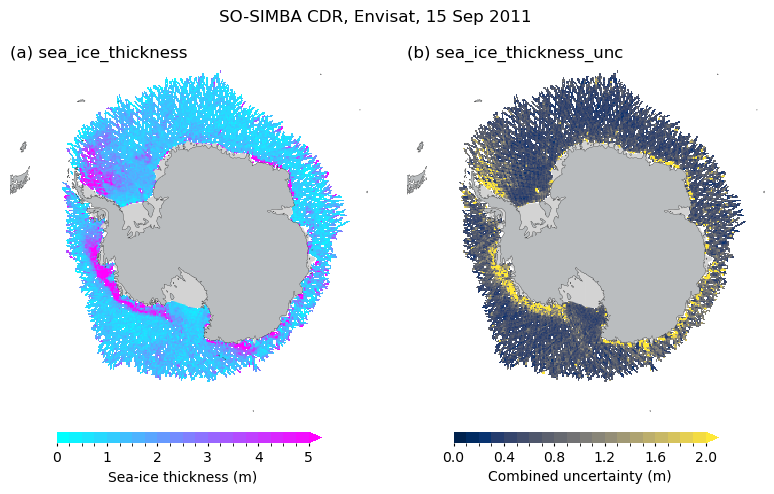

In [11]:
crs = ccrs.LambertAzimuthalEqualArea(central_longitude=0, central_latitude=-90)
extent = [-3.9e6, 3.9e6, -3.9e6, 3.9e6]   # x0, x1, y0, y1 in metres

land = cfeature.NaturalEarthFeature("physical", "coastline", "50m", facecolor=(0.73, 0.74, 0.75), edgecolor="black")
shelves = cfeature.NaturalEarthFeature("physical", "antarctic_ice_shelves_polys", "50m", facecolor="lightgray",
                                       edgecolor="lightgray")


def plot_map(ax, da, cmap, vmin, vmax, label, n_steps=20):
    """Map of a 2-D field of the CDR on the EASE2 grid, with n_steps colour levels between vmin and vmax."""
    levels = np.linspace(vmin, vmax, n_steps + 1)
    cmap = plt.get_cmap(cmap, n_steps + 1)                      
    norm = BoundaryNorm(levels, ncolors=cmap.N, extend="max")
    ax.set_extent(extent, crs=crs)
    im = ax.pcolormesh(da.xc, da.yc, da.squeeze(), cmap=cmap, norm=norm, transform=crs,
                       shading="auto", rasterized=True)
    ax.add_feature(shelves, linewidth=0.2, zorder=2)
    ax.add_feature(land, linewidth=0.2, zorder=3)
    ax.axis("off")
    cb = plt.colorbar(im, ax=ax, orientation="horizontal", shrink=0.7, pad=0.02, aspect=25, extend="max")
    cb.set_label(label)
    cb.set_ticks(levels[::4])
    cb.outline.set_visible(False)
    cb.ax.tick_params(length=2)
    return im


name = {"envisat": "Envisat", "cryosat2": "CryoSat-2"}[MISSION]
fig, axes = plt.subplots(1, 2, figsize=(10, 5.6), subplot_kw={"projection": crs})
plot_map(axes[0], ds_day.sea_ice_thickness, "cool", 0, 5, "Sea-ice thickness (m)")
plot_map(axes[1], ds_day.sea_ice_thickness_unc, "cividis", 0, 2, "Combined uncertainty (m)")
axes[0].set_title("(a) sea_ice_thickness", loc="left")
axes[1].set_title("(b) sea_ice_thickness_unc", loc="left")
fig.suptitle(f"SO-SIMBA CDR, {name}, {pd.Timestamp(DATE):%d %b %Y}")
fig.subplots_adjust(wspace=0.05)
plt.show()

## 3. Time series of the mean sea-ice thickness

Mean over all valid grid cells, for every day between `START` and `END`: the period is selected in the store and
averaged in one go (about 20 s for one year).

In [12]:
START, END = "2010-01-01", "2011-12-31"
ds_year = ds.sel(time=slice(START, END))
ts = ds_year.sea_ice_thickness.mean(dim=['yc', 'xc'], skipna=True).compute()
ts

<xarray.DataArray 'sea_ice_thickness' (time: 730)> Size: 3kB
array([1.4543271, 1.4511701, 1.4661123, 1.4675232, 1.4756944, 1.4833045,
       1.4932493, 1.4894664, 1.5030227, 1.5001067, 1.5058323, 1.4980553,
       1.4954426, 1.5280079, 1.5194256, 1.5162241, 1.55153  , 1.5505303,
       1.5525874, 1.5762188, 1.5716281, 1.5739868, 1.5942557, 1.6201692,
       1.6107764, 1.619897 , 1.6347961, 1.6307843, 1.6614275, 1.6749307,
       1.6886225, 1.6950717, 1.7223207, 1.6975427, 1.7066804, 1.7229596,
       1.7289534, 1.7379578, 1.7332493, 1.7015662, 1.687948 , 1.676833 ,
       1.6862446, 1.6925799, 1.6890942, 1.6945438, 1.6758991, 1.6655922,
       1.6419264, 1.5953306, 1.5800999, 1.5533862, 1.5142046, 1.5100937,
       1.4736302, 1.470214 , 1.4620891, 1.4341533, 1.4202498, 1.402949 ,
       1.4008214, 1.3865327, 1.3888766, 1.4002916, 1.4175953, 1.4129809,
       1.4287617, 1.4291699, 1.4343957, 1.4242731, 1.4257255, 1.4328772,
       1.4279544, 1.4297142, 1.410875 , 1.4151727, 1.4338292, 1.4218764,
       1.4201058, 1.4105369, 1.407175 , 1.3965449, 1.4042178, 1.4079432,
       1.4029652, 1.415594 , 1.4335827, 1.4284333, 1.4457428, 1.4465399,
       1.4228342, 1.4195049, 1.4323424, 1.4089421, 1.4053735, 1.3956691,
       1.38654  , 1.372034 , 1.3771164, 1.3759106, 1.3782896, 1.3780425,
       1.3948377, 1.3970268, 1.3890669, 1.383475 , 1.3830178, 1.3728853,
       1.3810446, 1.3750342, 1.3744901, 1.3862339, 1.3767369, 1.371431 ,
       1.3648028, 1.3690856, 1.3696727, 1.3620186, 1.3617008, 1.3691052,
...
       1.6726817, 1.6671635, 1.6636167, 1.6551977, 1.6410459, 1.6358349,
       1.6294421, 1.628288 , 1.6243253, 1.6285123, 1.6216341, 1.6194814,
       1.6199856, 1.6133617, 1.6164219, 1.6207048, 1.6270424, 1.6269081,
       1.6337079, 1.6431583, 1.6380996, 1.6394279, 1.6406829, 1.6385547,
       1.6313874, 1.6337404, 1.6296678, 1.6192341, 1.6097342, 1.6077616,
       1.606777 , 1.6030076, 1.5943668, 1.5950267, 1.5909818, 1.5932148,
       1.5922843, 1.5870925, 1.5862141, 1.5838462, 1.582468 , 1.5791205,
       1.5763941, 1.5699426, 1.5656284, 1.5566926, 1.547348 , 1.5361186,
       1.5243573, 1.5107117, 1.5035417, 1.4930679, 1.4824284, 1.4736584,
       1.4572275, 1.4442707, 1.4299737, 1.4169526, 1.4138114, 1.4042797,
       1.3907254, 1.3807327, 1.3745795, 1.3655144, 1.3556906, 1.3474977,
       1.3401494, 1.3246199, 1.3152821, 1.30629  , 1.2948297, 1.283728 ,
       1.2883275, 1.2742723, 1.262818 , 1.2610668, 1.2628937, 1.2543145,
       1.248075 , 1.2527221, 1.2426484, 1.2458233, 1.2340697, 1.2306366,
       1.2405931, 1.236835 , 1.2363479, 1.2367923, 1.2481871, 1.2455156,
       1.2541301, 1.2578337, 1.2690505, 1.2682116, 1.2784464, 1.2910242,
       1.3071862, 1.3237925, 1.338798 , 1.3530455, 1.3627893, 1.3752257,
       1.3810765, 1.4007181, 1.4189544, 1.4172676, 1.4424269, 1.4557028,
       1.456869 , 1.4757146, 1.4936959, 1.495236 , 1.5181658, 1.5387864,
       1.5522147, 1.5590771, 1.5722543, 1.5991664], dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 6kB 2010-01-01T12:00:00 ... 2011-12-31T12:...
Attributes:
    long_name:              thickness of the sea ice layer
    standard_name:          sea_ice_thickness
    units:                  m
    grid_mapping:           crs
    comment:                weighted mean of the sea-ice thickness
    coverage_content_type:  physicalMeasurement

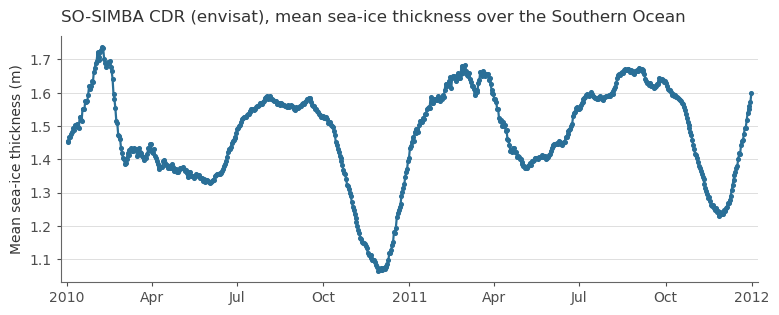

In [13]:
COLOR = "#2a6f97"   # ocean blue
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(ts.time, ts.values, color=COLOR, lw=1.6)
ax.scatter(ts.time, ts.values, color=COLOR, s=7, zorder=3)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
for s in ("left", "bottom"):
    ax.spines[s].set_color("0.4")
ax.tick_params(colors="0.3", length=3)
ax.grid(axis="y", color="0.85", lw=0.6)
ax.set_axisbelow(True)
ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=10))
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.set_ylabel("Mean sea-ice thickness (m)", color="0.2")
ax.set_title(f"SO-SIMBA CDR ({MISSION}), mean sea-ice thickness over the Southern Ocean", loc="left", color="0.2", pad=10)
ax.margins(x=0.01)
plt.show()

## References

Bocquet, M. and Ricker, R.: SO-SIMBA Climate Data record of Antarctic Sea Ice Thickness and Sea Ice Volume,
Norwegian Meteorological Institute / Arctic Data Centre, https://doi.org/10.21343/pf9r-6d17.

# SO-SIMBA MMS – Antarctic sea-ice thickness

## Overview

| | |
|---|---|
| **Product** | Merged Multi-Sensor (MMS) sea-ice thickness and volume from CryoSat-2, Sentinel-3A and Sentinel-3B, drift-aware gridding |
| **Producers** | Marion Bocquet, Robert Ricker (NORCE Norwegian Research Centre) |
| **Time coverage** | 14 October 2018 – 31 August 2025, daily |
| **Grid** | 12.5 km EASE2, Southern Hemisphere (EPSG:6932) |
| **DOI** | *to be added* |
| **Data server** | [THREDDS catalogue](https://thredds.met.no/thredds/catalog/arcticdata/SO-SIMBA/SOSIMBA_MMS_SIT_vf/catalog.html) (OPeNDAP, HTTP, WMS) |
| **Zarr store** | `https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/so-simba/SOSIMBA_MMS_SIT_vf.zarr/` |
| **Licence** | CC-BY-4.0 |
| **Project** | ESA Polar Science Cluster, SO-SIMBA |

This notebook reads the data **remotely, without downloading anything**, from the cloud-optimised **zarr** copy
of the product (all days in one dataset):

1. Open the dataset and select one day
2. Maps of the merged sea-ice thickness and its combined uncertainty, and of the thickness from each sensor
3. Time series of the mean sea-ice thickness over a period

In [1]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
import numpy as np
import pandas as pd
import xarray as xr

# ---- to adapt
DATE = "2022-09-15"   # day to map (Oct 2018 - Aug 2025)

## Data access

The whole record is a single cloud-optimised **zarr** store on the EarthCODE object storage.
`xarray` opens it lazily: only the chunks you use are transferred, so a map or a multi-year time series is read
directly, without looping over files. Requires the `zarr`, `fsspec`, `aiohttp` and `dask` packages
(`pip install zarr fsspec aiohttp dask`).

In [3]:
ZARR = "https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/so-simba/SOSIMBA_MMS_SIT_vf.zarr/"


## 1. Open the dataset and select one day

In [4]:
ds = xr.open_dataset(ZARR, engine="zarr", chunks={}) # all days, nothing loaded yet
print(f"{ds.sizes['time']} days, {ds.time.values[0]:.10} to {ds.time.values[-1]:.10}")
ds_day = ds.sel(time=DATE, method="nearest")         # one day

# variables, units and description
for v in ds_day.data_vars:
    print(f"{v:40s} {ds_day[v].attrs.get('units', ''):8s} {ds_day[v].attrs.get('long_name', '')}")

2443 days, 2018-10-14 to 2025-08-31
crs                                               
cryosat2_cnt                                      number of data from CryoSat-2 in the grid cell
cryosat2_frac                                     fraction of data from CryoSat-2 in the grid cell
dist_acquisition                         km       distance between target day and day of data acquisition location
ku_freeboard                             m        ku-band radar freeboard
ku_freeboard_unc                         m        ku-band radar freeboard uncertainty
region                                   1        region identifier
sea_ice_thickness                        m        thickness of the sea ice layer
sea_ice_thickness_change                 m d-1    rate of change in sea ice thickness per day
sea_ice_thickness_change_interp          m d-1    interpolated sea ice thickness change
sea_ice_thickness_change_unc             m d-1    sea ice thickness uncertainty associated with the sea ice thi

## 2. Maps

The grid is a Lambert azimuthal equal-area projection centred on the South Pole (EASE2, EPSG:6932);
`xc` and `yc` are in metres.

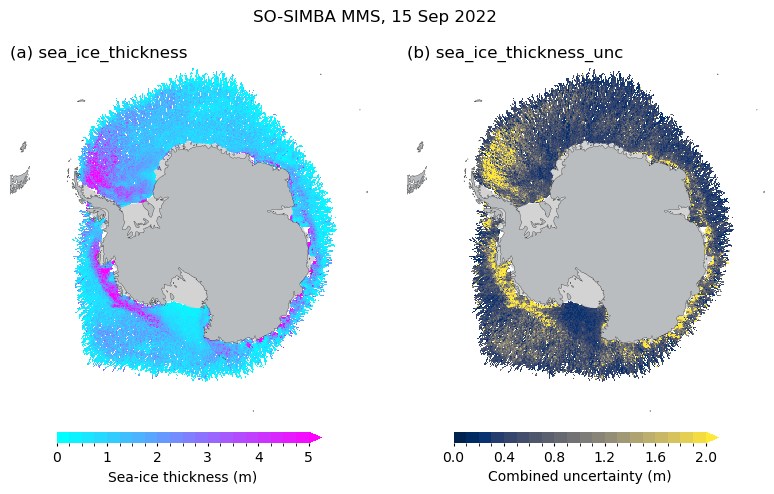

In [5]:
crs = ccrs.LambertAzimuthalEqualArea(central_longitude=0, central_latitude=-90)
extent = [-3.9e6, 3.9e6, -3.9e6, 3.9e6]   # x0, x1, y0, y1 in metres

land = cfeature.NaturalEarthFeature("physical", "coastline", "50m", facecolor=(0.73, 0.74, 0.75), edgecolor="black")
shelves = cfeature.NaturalEarthFeature("physical", "antarctic_ice_shelves_polys", "50m", facecolor="lightgray",
                                       edgecolor="lightgray")


def plot_map(ax, da, cmap, vmin, vmax, label, n_steps=20):
    """Map of a 2-D field on the EASE2 grid, with n_steps colour levels between vmin and vmax."""
    levels = np.linspace(vmin, vmax, n_steps + 1)
    cmap = plt.get_cmap(cmap, n_steps + 1)                      # + 1 colour for values above vmax
    norm = BoundaryNorm(levels, ncolors=cmap.N, extend="max")
    ax.set_extent(extent, crs=crs)
    im = ax.pcolormesh(da.xc, da.yc, da.squeeze(), cmap=cmap, norm=norm, transform=crs,
                       shading="auto", rasterized=True)
    ax.add_feature(shelves, linewidth=0.2, zorder=2)
    ax.add_feature(land, linewidth=0.2, zorder=3)
    ax.axis("off")
    cb = plt.colorbar(im, ax=ax, orientation="horizontal", shrink=0.7, pad=0.02, aspect=25, extend="max")
    cb.set_label(label)
    cb.set_ticks(levels[::4])
    cb.outline.set_visible(False)
    cb.ax.tick_params(length=2)
    return im


fig, axes = plt.subplots(1, 2, figsize=(10, 5.6), subplot_kw={"projection": crs})
plot_map(axes[0], ds_day.sea_ice_thickness, "cool", 0, 5, "Sea-ice thickness (m)")
plot_map(axes[1], ds_day.sea_ice_thickness_unc, "cividis", 0, 2, "Combined uncertainty (m)")
axes[0].set_title("(a) sea_ice_thickness", loc="left")
axes[1].set_title("(b) sea_ice_thickness_unc", loc="left")
fig.suptitle(f"SO-SIMBA MMS, {pd.Timestamp(ds_day.time.values):%d %b %Y}")
fig.subplots_adjust(wspace=0.05)
plt.show()

The file also contains the thickness from each sensor before merging (`sea_ice_thickness_<sensor>`).

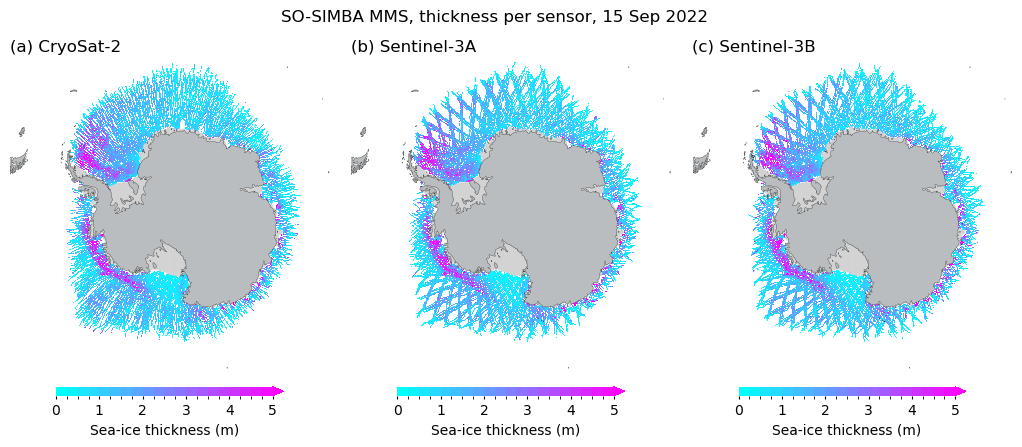

In [6]:
sensors = {"cryosat2": "CryoSat-2", "sentinel3a": "Sentinel-3A", "sentinel3b": "Sentinel-3B"}
fig, axes = plt.subplots(1, 3, figsize=(13, 5), subplot_kw={"projection": crs})
for k, (s, name) in enumerate(sensors.items()):
    plot_map(axes[k], ds_day[f"sea_ice_thickness_{s}"], "cool", 0, 5, "Sea-ice thickness (m)")
    axes[k].set_title(f"({'abc'[k]}) {name}", loc="left")
fig.suptitle(f"SO-SIMBA MMS, thickness per sensor, {pd.Timestamp(ds_day.time.values):%d %b %Y}")
fig.subplots_adjust(wspace=0.05)
plt.show()

## 3. Time series of the mean sea-ice thickness

Mean over all valid grid cells, for every day between `START` and `END`: the period is selected in the store and
averaged in one go.

In [7]:
START, END = "2022-01-01", "2022-12-31"
ds_year = ds.sel(time=slice(START, END))
ts = ds_year.sea_ice_thickness.mean(dim=['yc', 'xc'], skipna=True).compute()
ts

<xarray.DataArray 'sea_ice_thickness' (time: 365)> Size: 1kB
array([0.9030306 , 0.902595  , 0.90329266, 0.90642494, 0.90434414,
       0.89959157, 0.9023896 , 0.91235715, 0.90985423, 0.9105339 ,
       0.9100091 , 0.9061665 , 0.9073431 , 0.9151504 , 0.9221268 ,
       0.92631394, 0.9350467 , 0.9458479 , 0.95330536, 0.9559369 ,
       0.96392006, 0.9704563 , 0.9784848 , 0.9871377 , 0.98998576,
       0.9953626 , 0.9985154 , 1.0107392 , 1.028599  , 1.0370578 ,
       1.0536464 , 1.0597897 , 1.0686468 , 1.0703809 , 1.0814494 ,
       1.087185  , 1.1005728 , 1.1115385 , 1.1136078 , 1.116053  ,
       1.1257609 , 1.1304723 , 1.1422687 , 1.1548911 , 1.1640565 ,
       1.1784246 , 1.1869909 , 1.1766115 , 1.1780671 , 1.1791167 ,
       1.1839229 , 1.1904498 , 1.2059064 , 1.2192218 , 1.2169826 ,
       1.2160889 , 1.2197553 , 1.229766  , 1.224502  , 1.2251363 ,
       1.2239363 , 1.2280344 , 1.2180804 , 1.2201555 , 1.2193116 ,
       1.214488  , 1.2143341 , 1.2043259 , 1.1935827 , 1.1918811 ,
       1.20195   , 1.1850761 , 1.1792876 , 1.1821707 , 1.1795398 ,
       1.1880295 , 1.1783903 , 1.1805462 , 1.1744976 , 1.1742545 ,
       1.1580464 , 1.176347  , 1.16799   , 1.1519896 , 1.1469601 ,
       1.1433636 , 1.1416129 , 1.1283427 , 1.1139523 , 1.101481  ,
       1.096894  , 1.099538  , 1.0999484 , 1.0898712 , 1.0806564 ,
       1.0675501 , 1.0559285 , 1.0563992 , 1.0531609 , 1.0453503 ,
...
       1.3939674 , 1.3890249 , 1.3820546 , 1.3785436 , 1.375322  ,
       1.3709177 , 1.3638669 , 1.3564816 , 1.352613  , 1.344906  ,
       1.3377426 , 1.3269435 , 1.3256829 , 1.3222514 , 1.3193328 ,
       1.3129839 , 1.3018018 , 1.2942966 , 1.2856597 , 1.277006  ,
       1.2719529 , 1.268859  , 1.2637032 , 1.2541376 , 1.2465504 ,
       1.2368068 , 1.2301382 , 1.2167202 , 1.2070287 , 1.1920962 ,
       1.1799546 , 1.1695276 , 1.1622221 , 1.1557218 , 1.1480609 ,
       1.1400356 , 1.1322409 , 1.1252795 , 1.1205024 , 1.1106778 ,
       1.1053277 , 1.0991911 , 1.0919622 , 1.0842036 , 1.0789374 ,
       1.0716333 , 1.0644193 , 1.0563128 , 1.0503116 , 1.041428  ,
       1.0321413 , 1.0225637 , 1.0044739 , 0.99403214, 0.9824394 ,
       0.971437  , 0.96268773, 0.9544425 , 0.94584256, 0.93329084,
       0.92532295, 0.9196773 , 0.9108113 , 0.9064144 , 0.90052444,
       0.893296  , 0.8888293 , 0.88068587, 0.8779246 , 0.8675484 ,
       0.85995305, 0.8564611 , 0.85509425, 0.85282284, 0.8544654 ,
       0.8579798 , 0.8592474 , 0.8624155 , 0.8675903 , 0.8684712 ,
       0.86458033, 0.8672151 , 0.86876017, 0.87154335, 0.8695809 ,
       0.8731759 , 0.8736069 , 0.8837817 , 0.88808405, 0.8900374 ,
       0.8896561 , 0.89359885, 0.9048195 , 0.9135061 , 0.9237776 ],
      dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 3kB 2022-01-01T12:00:00 ... 2022-12-31T12:...
Attributes:
    long_name:              thickness of the sea ice layer
    standard_name:          sea_ice_thickness
    units:                  m
    grid_mapping:           crs
    comment:                weighted mean of the sea-ice thickness
    coverage_content_type:  physicalMeasurement

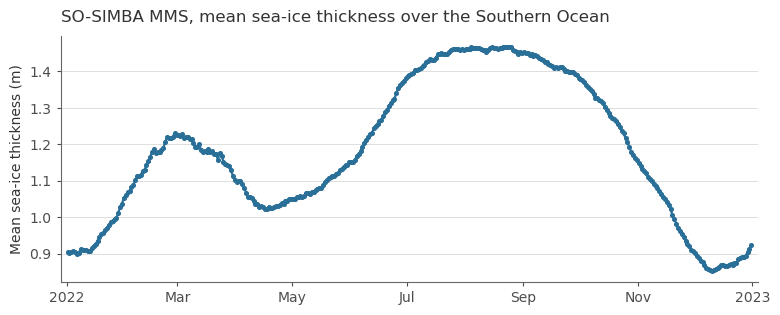

In [8]:
COLOR = "#2a6f97"   # ocean blue
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(ts.time, ts.values, color=COLOR, lw=1.6)
ax.scatter(ts.time, ts.values, color=COLOR, s=7, zorder=3)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
for s in ("left", "bottom"):
    ax.spines[s].set_color("0.4")
ax.tick_params(colors="0.3", length=3)
ax.grid(axis="y", color="0.85", lw=0.6)
ax.set_axisbelow(True)
ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=10))
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.set_ylabel("Mean sea-ice thickness (m)", color="0.2")
ax.set_title("SO-SIMBA MMS, mean sea-ice thickness over the Southern Ocean", loc="left", color="0.2", pad=10)
ax.margins(x=0.01)
plt.show()

## References

Bocquet, M. and Ricker, R.: SO-SIMBA Merged Multi Sensor of Sea Ice Thickness and Sea Ice Volume (Antarctic sea ice),
Norwegian Meteorological Institute / Arctic Data Centre, DOI to be added.

# SO-SIMBA MMS – snow depth on Antarctic sea ice

## Overview

| | |
|---|---|
| **Product** | Merged Multi-Sensor (MMS) snow depth on sea ice from laser (ICESat-2) and radar (CryoSat-2, Sentinel-3A, Sentinel-3B) freeboards |
| **Producers** | Marion Bocquet, Robert Ricker (NORCE Norwegian Research Centre) |
| **Time coverage** | 14 October 2018 – 31 August 2025, daily |
| **Grid** | 25 km EASE2, Southern Hemisphere (EPSG:6932) |
| **DOI** | *to be added* |
| **Data server** | [THREDDS catalogue](https://thredds.met.no/thredds/catalog/arcticdata/SO-SIMBA/SOSIMBA_MMS_SD_vf/catalog.html) (OPeNDAP, HTTP, WMS) |
| **Zarr store** | `https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/so-simba/SOSIMBA_MMS_SD_vf.zarr/` |
| **Licence** | CC-BY-4.0 |
| **Project** | ESA Polar Science Cluster, SO-SIMBA |

This notebook reads the data **remotely, without downloading anything**, from the cloud-optimised **zarr** copy
of the product (all days in one dataset):

1. Open the dataset and select one day
2. Maps of the snow depth and its uncertainty, and of the laser and radar freeboards
3. Time series of the mean snow depth over a period

In [1]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
import numpy as np
import pandas as pd
import xarray as xr

# ---- to adapt
DATE = "2022-09-15"   # day to map (Oct 2018 - Aug 2025)

## Data access

The whole record is a single cloud-optimised **zarr** store on the EarthCODE object storage.
`xarray` opens it lazily: only the chunks you use are transferred, so a map or a multi-year time series is read
directly, without looping over files. Requires the `zarr`, `fsspec`, `aiohttp` and `dask` packages
(`pip install zarr fsspec aiohttp dask`).

In [3]:
ZARR = "https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/so-simba/SOSIMBA_MMS_SD_vf.zarr/"

## 1. Open the dataset and select one day

In [4]:
ds = xr.open_dataset(ZARR, engine="zarr", chunks={})                                    # all days, nothing loaded yet
print(f"{ds.sizes['time']} days, {ds.time.values[0]:.10} to {ds.time.values[-1]:.10}")
ds_day = ds.sel(time=DATE, method="nearest")         # one day

# variables, units and description
for v in ds_day.data_vars:
    print(f"{v:40s} {ds_day[v].attrs.get('units', ''):8s} {ds_day[v].attrs.get('long_name', '')}")

2444 days, 2018-10-14 to 2025-08-31
crs                                               
ku_freeboard_interp                      m        ku-band radar freeboard interpolated
ku_freeboard_interp_unc                  m        ku-band radar freeboard uncertainty interpolated
ku_freeboard_raw                         m        ku-band radar freeboard
ku_freeboard_raw_unc                     m        ku-band radar freeboard uncertainty
region                                   1        region identifier
rolling_median_total_freeboard_interp    m        3-day moving window temporal median of gap-filled total freeboard
rolling_std_total_freeboard              m        temporal standard deviation of total freeboard calculated over a 3-day moving window
snow_density                             kg m-3   density of the snow layer
snow_depth                               m        thickness of the snow layer
snow_depth_unc                           m        uncertainty thickness of the snow layer
snow

## 2. Maps

The grid is a Lambert azimuthal equal-area projection centred on the South Pole (EASE2, EPSG:6932);
`xc` and `yc` are in metres.

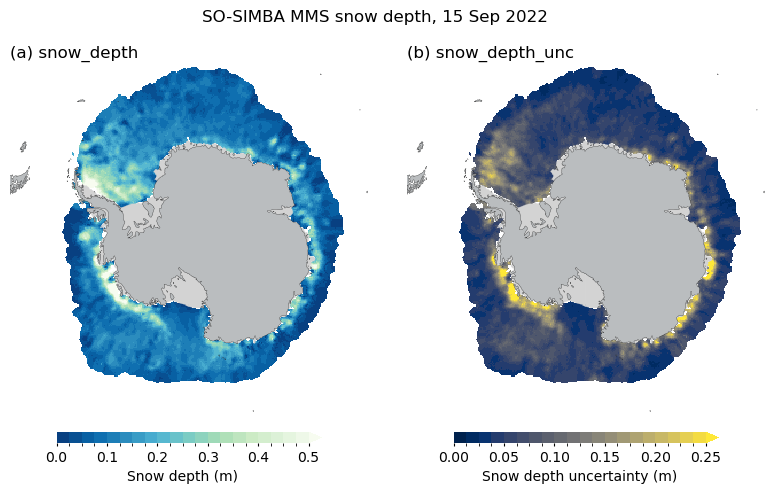

In [5]:
crs = ccrs.LambertAzimuthalEqualArea(central_longitude=0, central_latitude=-90)
extent = [-3.9e6, 3.9e6, -3.9e6, 3.9e6]   # x0, x1, y0, y1 in metres

land = cfeature.NaturalEarthFeature("physical", "coastline", "50m", facecolor=(0.73, 0.74, 0.75), edgecolor="black")
shelves = cfeature.NaturalEarthFeature("physical", "antarctic_ice_shelves_polys", "50m", facecolor="lightgray",
                                       edgecolor="lightgray")


def plot_map(ax, da, cmap, vmin, vmax, label, n_steps=20):
    """Map of a 2-D field on the EASE2 grid, with n_steps colour levels between vmin and vmax."""
    levels = np.linspace(vmin, vmax, n_steps + 1)
    cmap = plt.get_cmap(cmap, n_steps + 1)                      # + 1 colour for values above vmax
    norm = BoundaryNorm(levels, ncolors=cmap.N, extend="max")
    ax.set_extent(extent, crs=crs)
    im = ax.pcolormesh(da.xc, da.yc, da.squeeze(), cmap=cmap, norm=norm, transform=crs,
                       shading="auto", rasterized=True)
    ax.add_feature(shelves, linewidth=0.2, zorder=2)
    ax.add_feature(land, linewidth=0.2, zorder=3)
    ax.axis("off")
    cb = plt.colorbar(im, ax=ax, orientation="horizontal", shrink=0.7, pad=0.02, aspect=25, extend="max")
    cb.set_label(label)
    cb.set_ticks(levels[::4])
    cb.outline.set_visible(False)
    cb.ax.tick_params(length=2)
    return im


fig, axes = plt.subplots(1, 2, figsize=(10, 5.6), subplot_kw={"projection": crs})
plot_map(axes[0], ds_day.snow_depth, "GnBu_r", 0, 0.5, "Snow depth (m)")
plot_map(axes[1], ds_day.snow_depth_unc, "cividis", 0, 0.25, "Snow depth uncertainty (m)")
axes[0].set_title("(a) snow_depth", loc="left")
axes[1].set_title("(b) snow_depth_unc", loc="left")
fig.suptitle(f"SO-SIMBA MMS snow depth, {pd.Timestamp(ds_day.time.values):%d %b %Y}")
fig.subplots_adjust(wspace=0.05)
plt.show()

Snow depth is derived from the difference between the laser total freeboard and the Ku-band radar freeboard.

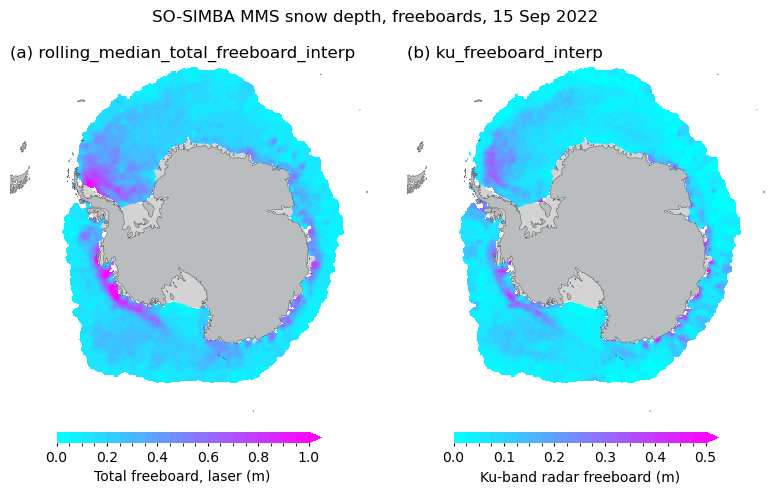

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5.6), subplot_kw={"projection": crs})
plot_map(axes[0], ds_day.rolling_median_total_freeboard_interp, "cool", 0, 1, "Total freeboard, laser (m)")
plot_map(axes[1], ds_day.ku_freeboard_interp, "cool", 0, 0.5, "Ku-band radar freeboard (m)")
axes[0].set_title("(a) rolling_median_total_freeboard_interp", loc="left")
axes[1].set_title("(b) ku_freeboard_interp", loc="left")
fig.suptitle(f"SO-SIMBA MMS snow depth, freeboards, {pd.Timestamp(ds_day.time.values):%d %b %Y}")
fig.subplots_adjust(wspace=0.05)
plt.show()

## 3. Time series of the mean snow depth

Mean over all valid grid cells, for every day between `START` and `END`: the period is selected in the store and
averaged in one go.

In [7]:
START, END = "2020-01-01", "2022-12-31"
ds_year = ds.sel(time=slice(START, END))
ts = ds_year.snow_depth.mean(dim=['yc', 'xc'], skipna=True).compute()
ts

<xarray.DataArray 'snow_depth' (time: 1096)> Size: 4kB
array([0.10150897, 0.10232192, 0.10058176, ..., 0.10725631, 0.10844582,
       0.10895556], shape=(1096,), dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 9kB 2020-01-01T12:00:00 ... 2022-12-31T12:...
Attributes:
    standard_name:          surface_snow_thickness
    long_name:              thickness of the snow layer
    units:                  m
    grid_mapping:           crs
    comment:                Snow thickness comming from the 3days_rolling_med...
    coverage_content_type:  auxiliaryInformation

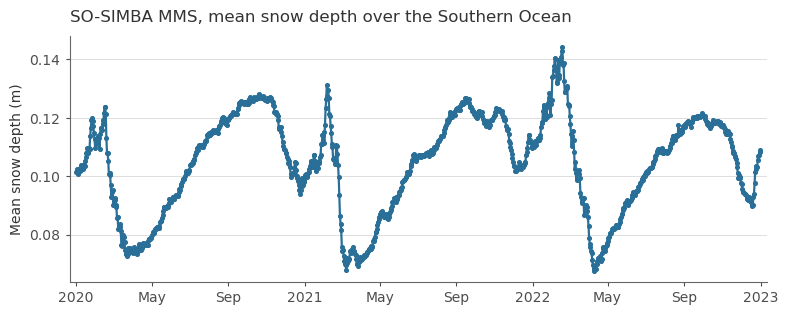

In [8]:
COLOR = "#2a6f97"   # ocean blue
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(ts.time, ts.values, color=COLOR, lw=1.6)
ax.scatter(ts.time, ts.values, color=COLOR, s=7, zorder=3)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
for s in ("left", "bottom"):
    ax.spines[s].set_color("0.4")
ax.tick_params(colors="0.3", length=3)
ax.grid(axis="y", color="0.85", lw=0.6)
ax.set_axisbelow(True)
ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=10))
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.set_ylabel("Mean snow depth (m)", color="0.2")
ax.set_title("SO-SIMBA MMS, mean snow depth over the Southern Ocean", loc="left", color="0.2", pad=10)
ax.margins(x=0.01)
plt.show()

## References

Bocquet, M. and Ricker, R.: SO-SIMBA Merged Multi Sensor of Snow Depth on Sea Ice (Antarctic sea ice),
Norwegian Meteorological Institute / Arctic Data Centre, DOI to be added.